# Data preparation

This notebook loads and cleans the Penguins data, then shows how each run's data is built: the split, the scaling, the synthetic data and the label noise. The code lives in `data_shapley/data.py`. Everything here uses seed 100.

- Penguins: 344 rows, 2 dropped for missing measurements, 342 kept (151 Adelie, 68 Chinstrap, 123 Gentoo).
- Penguins split: 205 train, 68 validation, 69 test. 41 training labels flipped.
- Gaussian data: 150 train, 90 validation, 1000 test. 30 training labels flipped.

## Setup
Run from the `notebooks/` folder.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent))  # so the notebook can import the project
from collections import Counter
import csv
import hashlib
import json
import numpy as np

from data_shapley.data import CLASS_LABELS, FEATURE_NAMES, load_penguins

csv_path = Path("../data/raw/penguins.csv")
provenance_path = csv_path.with_suffix(".provenance.json")
if not csv_path.is_file():
    raise FileNotFoundError("Open this notebook from notebooks/; the local data/raw/penguins.csv is required.")


## The source file
The CSV is the [official Palmer Penguins file](https://github.com/allisonhorst/palmerpenguins/blob/main/inst/extdata/penguins.csv), saved in `data/raw/`. We check it against its saved fingerprint.

Data by Kristen B. Gorman and Palmer Station Antarctica LTER, CC0 licence ([documentation](https://allisonhorst.github.io/palmerpenguins/)). Cite Horst, Hill & Gorman (2020), [doi:10.5281/zenodo.3960218](https://doi.org/10.5281/zenodo.3960218), and Gorman, Williams & Fraser (2014), [doi:10.1371/journal.pone.0090081](https://doi.org/10.1371/journal.pone.0090081).

In [2]:
provenance = json.loads(provenance_path.read_text(encoding="utf-8"))
source_bytes = csv_path.read_bytes()
checksum = hashlib.sha256(source_bytes).hexdigest()
assert checksum == provenance["sha256"], "Source checksum differs from the recorded download."
print("Source:", provenance["source_url"])
print("Downloaded (UTC):", provenance["downloaded_at_utc"])
print("SHA-256:", checksum)
print("License:", provenance["license"])


Source: https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv
Downloaded (UTC): 2026-10-26T21:41:03.004240+00:00
SHA-256: f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93
License: CC0-1.0


## Missing values
The features are bill length, bill depth, flipper length and body mass. The target is species. Sex is not used, so a missing sex does not drop a row.

Each row keeps its position in the original CSV as its id.

In [3]:
with csv_path.open(encoding="utf-8", newline="") as source:
    reader = csv.DictReader(source)
    raw_rows = list(reader)

print("Original data rows:", len(raw_rows))
print(f"{'Column':<22} {'Missing values':>14}")
for name in reader.fieldnames:
    missing_count = sum(row[name].strip() in {"", "NA"} for row in raw_rows)
    print(f"{name:<22} {missing_count:>14}")


Original data rows: 344
Column                 Missing values
species                             0
island                              0
bill_length_mm                      2
bill_depth_mm                       2
flipper_length_mm                   2
body_mass_g                         2
sex                                11
year                                0


## Cleaning
We drop rows with a missing measurement and change nothing else: no imputation, no outlier removal, no scaling.

The cleaning function, shown from [data_shapley/data.py](../data_shapley/data.py).

In [4]:
import inspect
print(inspect.getsource(load_penguins))


def load_penguins(csv_path: str | Path) -> PenguinData:
    """drop missing predictors only; missing unused fields should not discard a row. keep the raw csv unchanged."""
    features = []
    labels = []
    retained_ids = []
    dropped_ids = []
    n_raw = 0
    required = {"species", *FEATURE_NAMES}

    with Path(csv_path).open("r", encoding="utf-8-sig", newline="") as source:
        reader = csv.DictReader(source)
        header = reader.fieldnames or []
        missing = required.difference(header)
        if missing:
            raise ValueError(f"Missing required columns: {sorted(missing)}")
        if len(header) != len(set(header)):
            raise ValueError("Duplicate CSV column names are not allowed.")

        for observation_id, row in enumerate(reader):
            n_raw += 1
            if None in row or any(row[name] is None for name in required):
                raise ValueError(f"Malformed CSV row at observation_id={observation_id}")
            label = row["sp

In [5]:
penguins = load_penguins(csv_path)
print("Feature matrix shape:", penguins.X.shape)
print("Target shape:", penguins.y.shape)
print("Excluded observation IDs:", penguins.dropped_observation_ids.tolist())
print("\nRetained species counts:")
counts = Counter(penguins.y)
for species in CLASS_LABELS:
    print(f"{species:<12} {counts[species]:>3}")
print("\nExcluded rows (selected measurements):")
for observation_id in penguins.dropped_observation_ids:
    row = raw_rows[observation_id]
    print(int(observation_id), row["species"], {name: row[name] for name in FEATURE_NAMES})


Feature matrix shape: (342, 4)
Target shape: (342,)
Excluded observation IDs: [3, 271]

Retained species counts:
Adelie       151
Chinstrap     68
Gentoo       123

Excluded rows (selected measurements):
3 Adelie {'bill_length_mm': 'NA', 'bill_depth_mm': 'NA', 'flipper_length_mm': 'NA', 'body_mass_g': 'NA'}
271 Gentoo {'bill_length_mm': 'NA', 'bill_depth_mm': 'NA', 'flipper_length_mm': 'NA', 'body_mass_g': 'NA'}


## First rows
Lengths are in millimetres and mass in grams.

In [6]:
print(f"{'ID':>3} {'Species':<10} {'Bill length (mm)':>16} {'Bill depth (mm)':>15} {'Flipper (mm)':>12} {'Mass (g)':>9}")
for observation_id, label, values in zip(penguins.observation_ids[:5], penguins.y[:5], penguins.X[:5]):
    print(f"{observation_id:>3} {label:<10} {values[0]:>16.1f} {values[1]:>15.1f} {values[2]:>12.0f} {values[3]:>9.0f}")
print("\nObserved feature ranges (no values removed on this basis):")
for name, low, high in zip(FEATURE_NAMES, penguins.X.min(axis=0), penguins.X.max(axis=0)):
    print(f"{name:<20} {low:>7.1f} to {high:>7.1f}")


 ID Species    Bill length (mm) Bill depth (mm) Flipper (mm)  Mass (g)
  0 Adelie                 39.1            18.7          181      3750
  1 Adelie                 39.5            17.4          186      3800
  2 Adelie                 40.3            18.0          195      3250
  4 Adelie                 36.7            19.3          193      3450
  5 Adelie                 39.3            20.6          190      3650

Observed feature ranges (no values removed on this basis):
bill_length_mm          32.1 to    59.6
bill_depth_mm           13.1 to    21.5
flipper_length_mm      172.0 to   231.0
body_mass_g           2700.0 to  6300.0


## Checks
The data is complete, labels line up with rows, ids are stable and loading twice gives the same result.

In [7]:
assert penguins.n_raw == 344
assert penguins.X.shape == (342, 4)
assert dict(counts) == {"Adelie": 151, "Chinstrap": 68, "Gentoo": 123}
assert np.isfinite(penguins.X).all()
assert len(set(penguins.observation_ids)) == 342
assert set(penguins.observation_ids).isdisjoint(penguins.dropped_observation_ids)
assert set(penguins.observation_ids) | set(penguins.dropped_observation_ids) == set(range(344))
missing_sex_retained = sum(raw_rows[i]["sex"] == "NA" for i in penguins.observation_ids)
print("Retained rows with missing sex:", missing_sex_retained)
duplicate_feature_label_rows = len(penguins.y) - len(set(zip(map(tuple, penguins.X), penguins.y)))
print("Duplicate feature-and-label rows:", duplicate_feature_label_rows)
again = load_penguins(csv_path)
for name in ("X", "y", "observation_ids", "dropped_observation_ids"):
    np.testing.assert_array_equal(getattr(penguins, name), getattr(again, name))
assert source_bytes == csv_path.read_bytes()
print("All cleaning checks passed.")


Retained rows with missing sex: 9
Duplicate feature-and-label rows: 0
All cleaning checks passed.


# Building the data for one run

Steps: random generators, Penguins split, scaling, Gaussian data, label noise, checks. The sizes, noise rate and distributions were fixed in advance.

## Random generators
Each part of the data gets its own generator from the run's seed, so changing one part does not change the others.

In [8]:
from data_shapley.data import (
    make_data_rngs, split_penguins, standardize_split,
    generate_gaussian_split, corrupt_training_labels,
)

RUN_SEED = 100
rngs, seed_manifest = make_data_rngs(RUN_SEED)
print("Run seed:", RUN_SEED)
for name, state in seed_manifest["streams"].items():
    print(f"{name:<24} spawn_key={state['spawn_key']} generator={state['bit_generator']}")


Run seed: 100
penguins_split           spawn_key=[0, 0] generator=PCG64
penguins_noise           spawn_key=[0, 1] generator=PCG64
synthetic_train          spawn_key=[0, 2] generator=PCG64
synthetic_validation     spawn_key=[0, 3] generator=PCG64
synthetic_test           spawn_key=[0, 4] generator=PCG64
synthetic_noise          spawn_key=[0, 5] generator=PCG64


## Penguins split
Each species is split with fixed counts, about 60/20/20.

| Species | Train | Validation | Test |
|---|---:|---:|---:|
| Adelie | 90 | 30 | 31 |
| Chinstrap | 41 | 14 | 13 |
| Gentoo | 74 | 24 | 25 |

In [9]:
penguins_raw_split = split_penguins(penguins, rngs["penguins_split"])

def show_partition_counts(name, split):
    print(name)
    for partition_name in ("train", "validation", "test"):
        part = getattr(split, partition_name)
        print(f"{partition_name:<12} X={str(part.X.shape):<12} labels={dict(Counter(part.y.tolist()))}")

show_partition_counts("Penguins, original units and labels", penguins_raw_split)
penguin_ids = [getattr(penguins_raw_split, name).observation_ids for name in ("train", "validation", "test")]
assert len(np.unique(np.concatenate(penguin_ids))) == 342
assert set(np.concatenate(penguin_ids)) == set(penguins.observation_ids)
print("Disjoint partitions: 342 unique IDs assigned exactly once.")


Penguins, original units and labels
train        X=(205, 4)     labels={'Gentoo': 74, 'Adelie': 90, 'Chinstrap': 41}
validation   X=(68, 4)      labels={'Adelie': 30, 'Chinstrap': 14, 'Gentoo': 24}
test         X=(69, 4)      labels={'Gentoo': 25, 'Adelie': 31, 'Chinstrap': 13}
Disjoint partitions: 342 unique IDs assigned exactly once.


## Scaling
Each feature is standardized with the training mean and std only, so grams do not outweigh millimetres in the distances. The same scaling is applied to validation and test.

In [10]:
penguins_split, penguins_scaler = standardize_split(penguins_raw_split)
print(f"{'Feature':<22} {'Training mean':>15} {'Training std':>15} {'Zero variance':>15}")
for name, mean, std, zero in zip(FEATURE_NAMES, penguins_scaler.mean, penguins_scaler.std, penguins_scaler.zero_variance_mask):
    print(f"{name:<22} {mean:>15.6f} {std:>15.6f} {str(bool(zero)):>15}")
np.testing.assert_allclose(penguins_split.train.X.mean(axis=0), 0.0, atol=1e-12)
np.testing.assert_allclose(penguins_split.train.X.std(axis=0), 1.0, atol=1e-12)
for original, scaled in zip(
    (penguins_raw_split.train, penguins_raw_split.validation, penguins_raw_split.test),
    (penguins_split.train, penguins_split.validation, penguins_split.test),
):
    np.testing.assert_allclose(scaled.X, (original.X - penguins_scaler.mean) / penguins_scaler.scale)
    np.testing.assert_array_equal(original.y, scaled.y)
    np.testing.assert_array_equal(original.observation_ids, scaled.observation_ids)
print("All three partitions use identical original-training statistics.")


Feature                  Training mean    Training std   Zero variance
bill_length_mm               43.910244        5.572401           False
bill_depth_mm                17.150732        1.970109           False
flipper_length_mm           200.907317       13.965330           False
body_mass_g                4177.926829      800.352800           False
All three partitions use identical original-training statistics.


## Gaussian data
Two classes: class 0 around (-1, 0) and class 1 around (1, 0), both with identity covariance, so they overlap. Train, validation and test are drawn separately and balanced. The test set is large because it does not affect valuation cost. It is scaled the same way as Penguins.

In [11]:
synthetic_raw_split = generate_gaussian_split(
    rngs["synthetic_train"], rngs["synthetic_validation"], rngs["synthetic_test"]
)
synthetic_split, synthetic_scaler = standardize_split(synthetic_raw_split)
show_partition_counts("Synthetic, before label corruption", synthetic_split)
synthetic_ids = np.concatenate([
    getattr(synthetic_split, name).observation_ids for name in ("train", "validation", "test")
])
assert len(np.unique(synthetic_ids)) == 1240
np.testing.assert_allclose(synthetic_split.train.X.mean(axis=0), 0.0, atol=1e-12)
np.testing.assert_allclose(synthetic_split.train.X.std(axis=0), 1.0, atol=1e-12)
print("Synthetic training mean:", synthetic_scaler.mean)
print("Synthetic training std:", synthetic_scaler.std)
print("Independent partition streams and 1,240 unique IDs checked.")


Synthetic, before label corruption
train        X=(150, 2)     labels={0: 75, 1: 75}
validation   X=(90, 2)      labels={0: 45, 1: 45}
test         X=(1000, 2)    labels={0: 500, 1: 500}
Synthetic training mean: [0.03489202 0.05175916]
Synthetic training std: [1.42741971 1.00083113]
Independent partition streams and 1,240 unique IDs checked.


## Label noise
20% of training labels are flipped to a different class: 41 of 205 for Penguins and 30 of 150 for Gaussian. Only training labels change. We keep the clean labels and which rows were flipped.

In [12]:
penguins_holdout_labels = [penguins_split.validation.y.copy(), penguins_split.test.y.copy()]
synthetic_holdout_labels = [synthetic_split.validation.y.copy(), synthetic_split.test.y.copy()]
penguins_noise = corrupt_training_labels(penguins_split.train, 41, CLASS_LABELS, rngs["penguins_noise"])
synthetic_noise = corrupt_training_labels(synthetic_split.train, 30, (0, 1), rngs["synthetic_noise"])

for name, clean, noisy, n_flips in (
    ("Penguins", penguins_split.train, penguins_noise, 41),
    ("Synthetic", synthetic_split.train, synthetic_noise, 30),
):
    assert int(noisy.corruption_mask.sum()) == n_flips
    np.testing.assert_array_equal(noisy.corruption_mask, noisy.training.y != clean.y)
    np.testing.assert_array_equal(noisy.training.X, clean.X)
    np.testing.assert_array_equal(noisy.training.observation_ids, clean.observation_ids)
    np.testing.assert_array_equal(noisy.original_labels, clean.y)
    print(f"{name}: {n_flips}/{len(clean.y)} labels changed ({n_flips / len(clean.y):.0%}).")
    print("  Clean counts:", dict(Counter(clean.y.tolist())))
    print("  Noisy counts:", dict(Counter(noisy.training.y.tolist())))
    print("  First five corruption records (original observation ID, old label, new label):")
    for position in np.flatnonzero(noisy.corruption_mask)[:5]:
        print(" ", int(clean.observation_ids[position]), clean.y[position], "->", noisy.training.y[position])

for split, saved_labels in ((penguins_split, penguins_holdout_labels), (synthetic_split, synthetic_holdout_labels)):
    np.testing.assert_array_equal(split.validation.y, saved_labels[0])
    np.testing.assert_array_equal(split.test.y, saved_labels[1])
print("All validation and test labels are unchanged.")


Penguins: 41/205 labels changed (20%).
  Clean counts: {'Gentoo': 74, 'Adelie': 90, 'Chinstrap': 41}
  Noisy counts: {'Gentoo': 77, 'Adelie': 79, 'Chinstrap': 49}
  First five corruption records (original observation ID, old label, new label):
  289 Chinstrap -> Gentoo
  181 Gentoo -> Chinstrap
  107 Adelie -> Gentoo
  98 Adelie -> Chinstrap
  209 Gentoo -> Adelie
Synthetic: 30/150 labels changed (20%).
  Clean counts: {0: 75, 1: 75}
  Noisy counts: {1: 71, 0: 79}
  First five corruption records (original observation ID, old label, new label):
  16 0 -> 1
  85 1 -> 0
  84 1 -> 0
  43 0 -> 1
  121 1 -> 0
All validation and test labels are unchanged.


## Flipped labels in the Gaussian data
Same points in both panels. The ringed points are the 30 flipped ones.

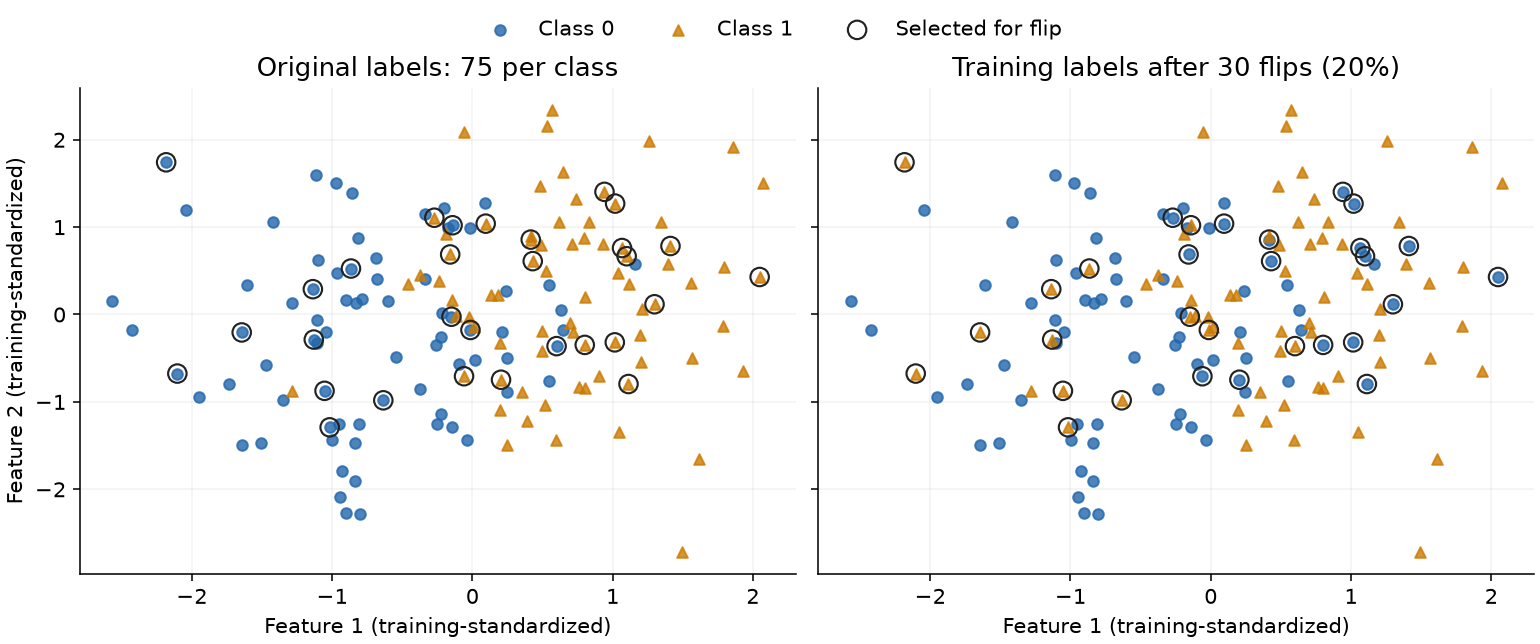

In [13]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import Image, display

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True, layout="constrained")
colors = {0: "#2166AC", 1: "#CC7A00"}
markers = {0: "o", 1: "^"}
X = synthetic_split.train.X
for ax, labels, title in zip(
    axes,
    (synthetic_noise.original_labels, synthetic_noise.training.y),
    ("Original labels: 75 per class", "Training labels after 30 flips (20%)"),
):
    for label in (0, 1):
        select = labels == label
        ax.scatter(X[select, 0], X[select, 1], s=30, alpha=0.8, color=colors[label], marker=markers[label], label=f"Class {label}")
    select = synthetic_noise.corruption_mask
    ax.scatter(X[select, 0], X[select, 1], s=90, facecolors="none", edgecolors="#222222", linewidths=1.1, label="Selected for flip")
    ax.set_title(title)
    ax.set_xlabel("Feature 1 (training-standardized)")
    ax.grid(alpha=0.15)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Feature 2 (training-standardized)")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=3, frameon=False)
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=140, facecolor="white")
display(Image(data=buffer.getvalue()))
plt.close(fig)


## Summary
The study rebuilds exactly this data for every seed. Next: the algorithm checks.